# 11.7 합성곱·장단기 메모리 순전파

시드 42의 난수 영상 4×1×28×28과 시퀀스 4×20×5를 사용합니다. 축과 출력 차원을 검산하기 위해 선택했으며 정답 라벨·모델 학습·성능 평가는 없습니다.

선정 이유: 시드 42의 난수 영상 4×1×28×28과 시퀀스 4×20×5를 사용합니다. 축과 출력 차원을 검산하기 위해 선택했으며 정답 라벨·모델 학습·성능 평가는 없습니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 신경망 모듈(Neural Network Module)의 별칭 nn를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import torch

# 가져오기(Import) 문장으로 신경망 모듈(Neural Network Module)의 별칭 nn를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import torch.nn as nn

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_07_main"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

앞 셀의 값을 사용해 torch.manual_seed(42) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

In [5]:
# 앞 셀의 값을 사용해 torch.manual_seed(42) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
torch.manual_seed(42)

Out[0]: <torch._C.Generator at 0x7f76546a1f30>


## 셀 6 함수와 모듈 정의

ConvNet의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.

In [6]:
# ConvNet의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Linear(16 * 14 * 14, 10)
    def forward(self, x):
        out = self.features(x)
        return self.classifier(out.flatten(1))

## 셀 7 함수와 모듈 정의

LSTMClassifier의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.

In [7]:
# LSTMClassifier의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.
class LSTMClassifier(nn.Module):
    def __init__(self, input_size=5, hidden_size=16, num_classes=3):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        return self.fc(output[:, -1, :])

## 셀 8 입력·계산·출력 확인

변수 cnn를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 lstm를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 image를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 sequence를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문맥 관리자(Context Manager)의 범위에서 자동 미분 기록이나 자원 사용을 제어합니다. 들여쓰기 밖의 계산과 구분합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for ax,a,t in zip(axes,[image[0,0].numpy(),cv,lv],["Random image","CNN logits (eval)","LSTM logits (eval)"]):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

CNN Input Shape: (4, 1, 28, 28)
CNN Output Shape: (4, 10)
LSTM Input Shape: (4, 20, 5)
LSTM Output Shape: (4, 3)
{
  "cnn_input": [
    4,
    1,
    28,
    28
  ],
  "cnn_output": [
    4,
    10
  ],
  "lstm_input": [
    4,
    20,
    5
  ],
  "lstm_output": [
    4,
    3
  ],
  "trained": false
}


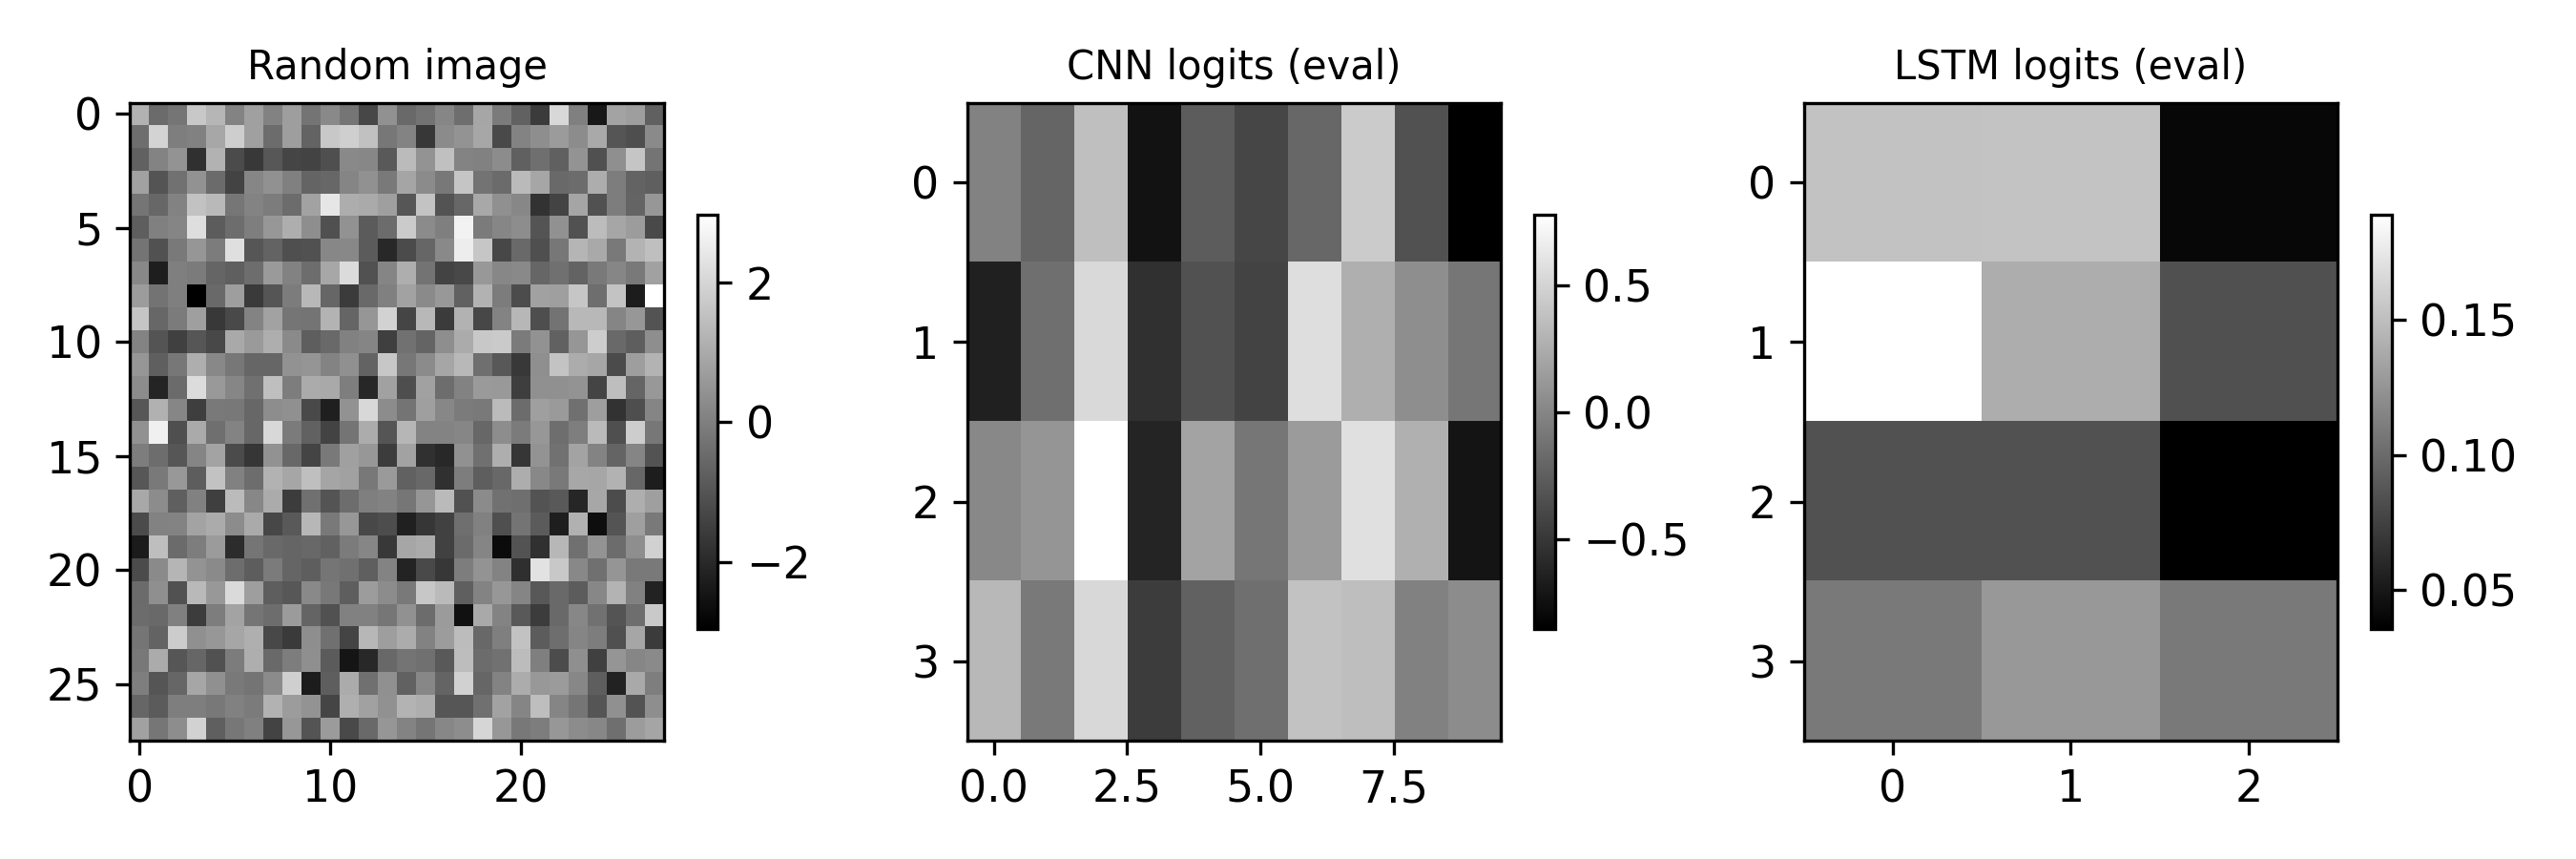

In [8]:
# 변수 cnn를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
cnn = ConvNet()

# 변수 lstm를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
lstm = LSTMClassifier()

# 변수 image를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
image = torch.randn(4, 1, 28, 28)

# 변수 sequence를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
sequence = torch.randn(4, 20, 5)

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"CNN Input Shape: {tuple(image.shape)}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"CNN Output Shape: {tuple(cnn(image).shape)}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"LSTM Input Shape: {tuple(sequence.shape)}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"LSTM Output Shape: {tuple(lstm(sequence).shape)}")

# 문맥 관리자(Context Manager)의 범위에서 자동 미분 기록이나 자원 사용을 제어합니다. 들여쓰기 밖의 계산과 구분합니다.
with torch.no_grad():
    cnn.eval();lstm.eval();cv=cnn(image).numpy();lv=lstm(sequence).numpy()

# 변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig,axes=plt.subplots(1,3,figsize=(9,3))

# 반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for ax,a,t in zip(axes,[image[0,0].numpy(),cv,lv],["Random image","CNN logits (eval)","LSTM logits (eval)"]):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.
for ax,a,t in zip(axes,[image[0,0].numpy(),cv,lv],["Random image","CNN logits (eval)","LSTM logits (eval)"]):
    im=ax.imshow(a,cmap="gray",aspect="auto");ax.set_title(t,fontsize=10);fig.colorbar(im,ax=ax,shrink=.65)

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"forward_outputs")

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"summary",{"cnn_input":list(image.shape),"cnn_output":list(cv.shape),"lstm_input":list(sequence.shape),"lstm_output":list(lv.shape),"trained":False})

## 그림과 결과 해석

영상과 로짓(Logits)은 난수 입력에 대한 순전파 출력입니다. 흑백 농도는 값이며 정확도·확률·학습 성능이 아닙니다.